In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    message=".*encountered in matmul.*"
)

In [3]:
df = pd.read_csv("insurance.csv")

print("Дубликатов:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])
df = df.drop_duplicates().reset_index(drop=True)

print("Строк после удаления:", len(df))
print("Дубликатов после удаления:", df.duplicated().sum())

Дубликатов: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Строк после удаления: 1337
Дубликатов после удаления: 0


In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   object 
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   object 
 5   region    1337 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.2+ KB


Отсутствующих значений нет.

In [10]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


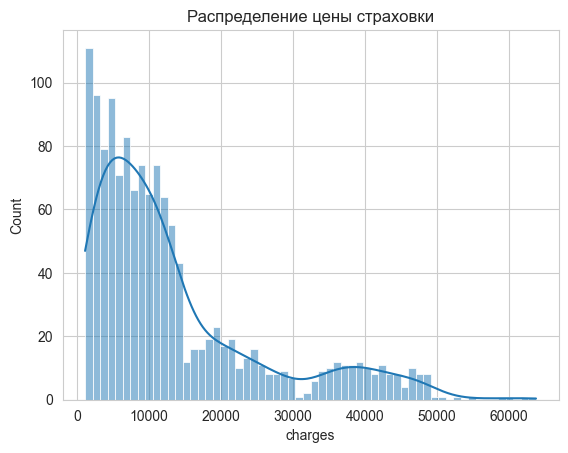

In [7]:
sns.histplot(df['charges'], bins = 60, kde = True)
plt.title("Распределение цены страховки")
plt.show()

На распределении таргета можно заметить правостороннюю асимметрию, это согласуется с данными, полученными при построении статистики.
Например:
    Разницей между медианным и средним значением. Среднее=13279 > медиана=9386 => выбросы в большую сторону.
    Распределением по четвертям. 75% клиентов имеют стоимость страховки меньше или равную 16658.

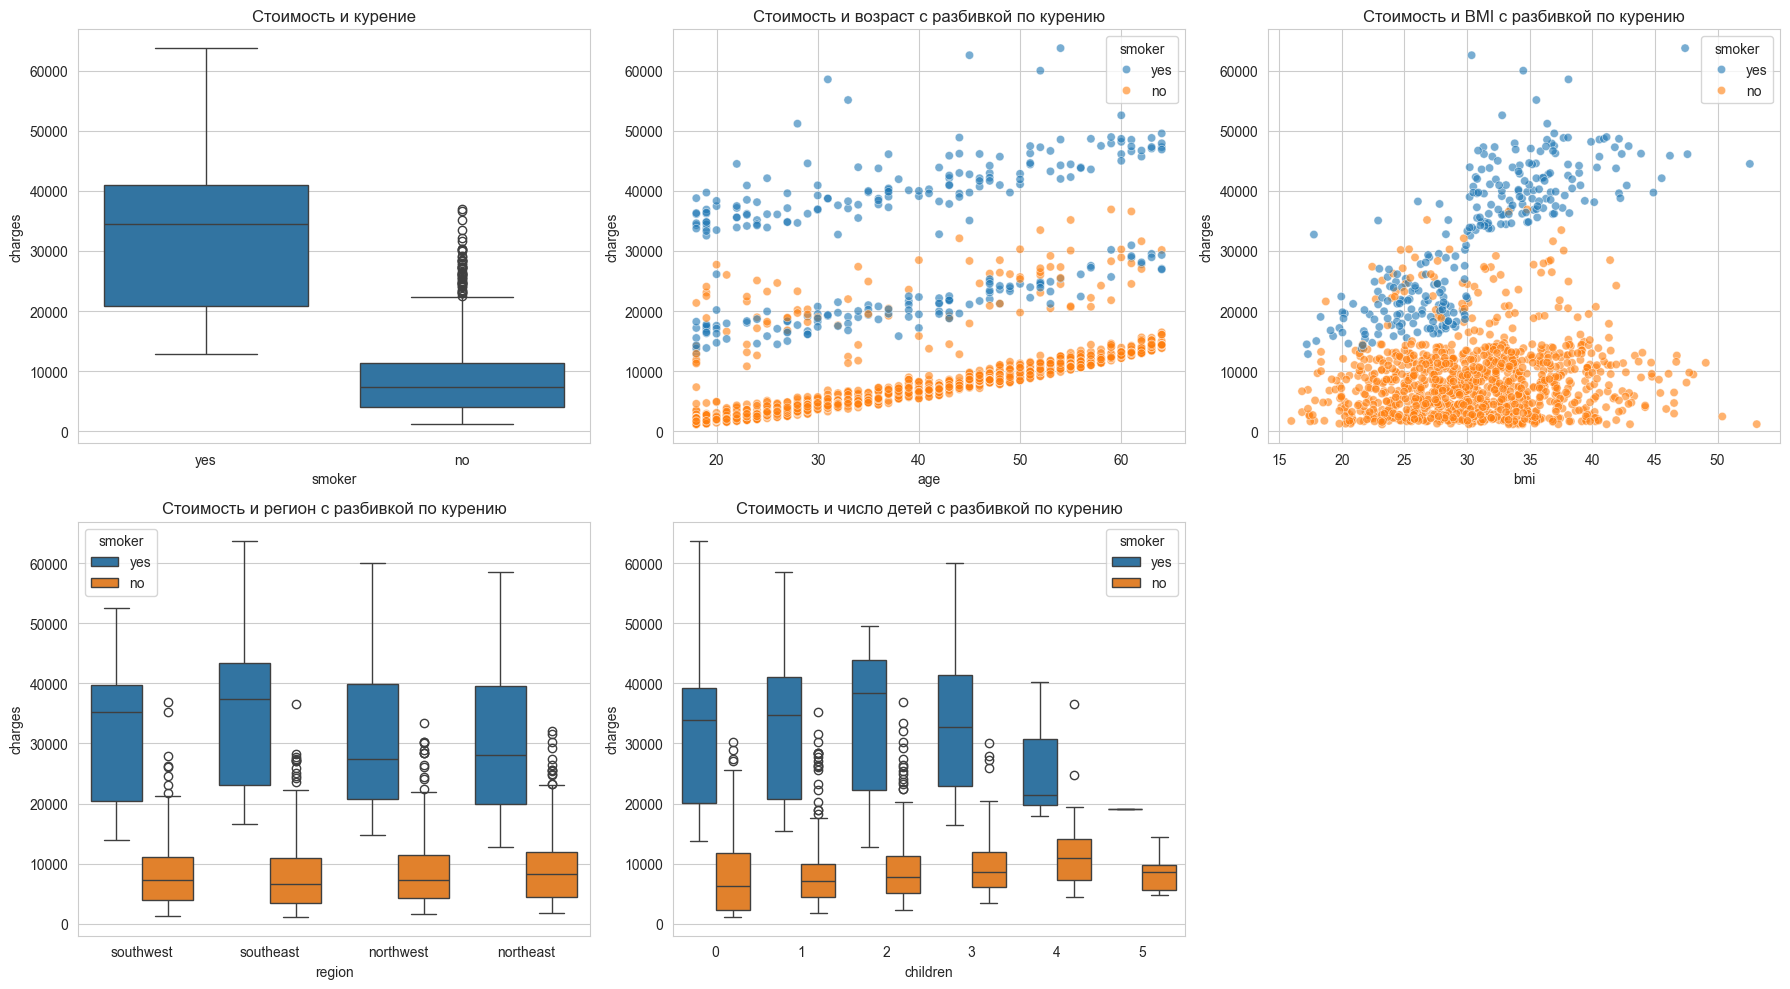

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.boxplot(data=df, x='smoker', y='charges', ax=axes[0, 0])
axes[0, 0].set_title('Стоимость и курение')

sns.scatterplot(
    data=df, x='age', y='charges',
    hue='smoker', alpha=0.6, ax=axes[0, 1]
)
axes[0, 1].set_title('Стоимость и возраст с разбивкой по курению')

sns.scatterplot(
    data=df, x='bmi', y='charges',
    hue='smoker', alpha=0.6, ax=axes[0, 2]
)
axes[0, 2].set_title('Стоимость и BMI с разбивкой по курению')

sns.boxplot(
    data=df, x='region', y='charges',
    hue='smoker', ax=axes[1, 0]
)
axes[1, 0].set_title('Стоимость и регион с разбивкой по курению')

sns.boxplot(
    data=df, x='children', y='charges',
    hue='smoker', ax=axes[1, 1]
)
axes[1, 1].set_title('Стоимость и число детей с разбивкой по курению')

fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

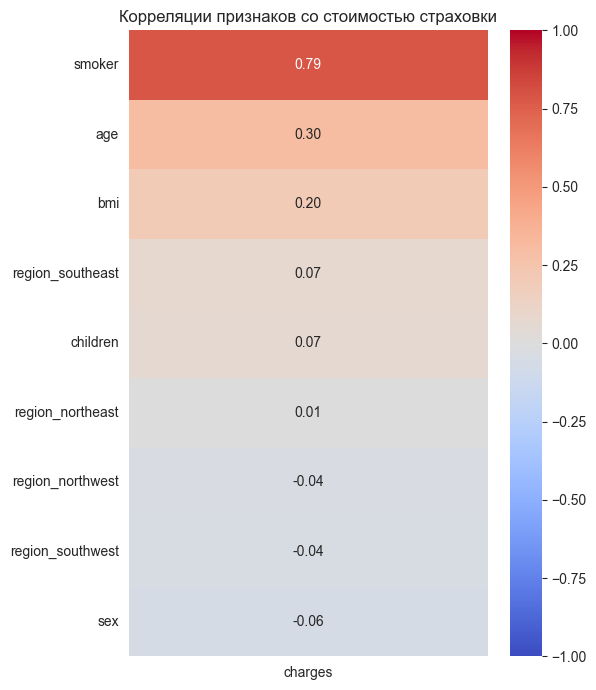

In [12]:
corr_df = df.copy()

corr_df['smoker'] = corr_df['smoker'].map({'no': 0, 'yes': 1})
corr_df['sex'] = corr_df['sex'].map({'male': 0, 'female': 1})

corr_df = pd.get_dummies(
    corr_df, columns=['region'], dtype=int
)
charges_corr = (
    corr_df.corr(method='pearson')['charges']
    .drop('charges')
    .sort_values(ascending=False)
)

plt.figure(figsize=(6, 7))
sns.heatmap(
    charges_corr.to_frame(name='charges'),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)
plt.title('Корреляции признаков со стоимостью страховки')
plt.tight_layout()
plt.show()

Были построены графики зависимости стоимости от каждого признака с разбивкой по smoker, и посчитаны корреляции.
Наиболее выраженная связь оказалась от курения: 0.79, у курящих медианная стоимость страховки значительно выше, что прослеживается и на других графиках, так как сделана разбивка по smoker.
Возраст так же положительно связан со стоимостью(0.3), на графике видно, что стоимость увеличивается с возрастом, как у курящих, так и у не курящих.
BMI слабо связан со стоимостью(0.2), однако на графике можно заметить, что у курящих высокие значения BMI, особенно >=30, связаны с заметно более высокими расходами.
Связь с количеством детей, регионом и полом очень слабая.

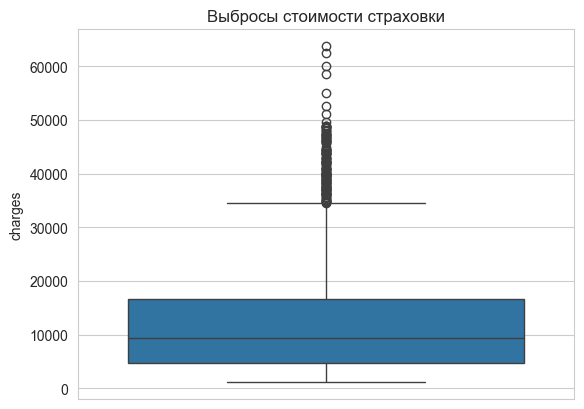

In [13]:
sns.boxplot(df['charges'])
plt.title("Выбросы стоимости страховки")
plt.show()

In [14]:
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['charges'] < lower_bound) | (df['charges'] > upper_bound)]

outliers.shape

(139, 7)

При помощи метода межквартального размаха, были найдены 139 возможных аномалий.

In [15]:
is_smoker = outliers['smoker'].eq('yes')
high_bmi = outliers['bmi'].ge(30)

display(pd.crosstab(
    outliers['smoker'],
    high_bmi.map({False: 'BMI < 30', True: 'BMI ≥ 30'}),
    rownames=['Курение'],
    colnames=['Группа BMI'],
    margins=True,
    margins_name='Всего'
))

matches = is_smoker & high_bmi
print(
    f'Курят и имеют BMI ≥ 30: '
    f'{matches.sum()} из {len(outliers)} '
    f'({matches.mean():.1%})'
)

print('Исключения:')
display(
    outliers.loc[
        ~matches,
        ['age', 'bmi', 'smoker', 'children', 'charges']
    ].sort_values('charges', ascending=False).sort_values('age')
)

Группа BMI,BMI < 30,BMI ≥ 30,Всего
Курение,,,
no,1,2,3
yes,4,132,136
Всего,5,134,139


Курят и имеют BMI ≥ 30: 132 из 139 (95.0%)
Исключения:


,age,bmi,smoker,children,charges
476,24,28.500,yes,0,35147.52848
524,42,26.070,yes,1,38245.59327
1302,43,27.800,yes,0,37829.72420
916,45,22.895,yes,0,35069.37452
242,55,26.800,no,1,35160.13457
1205,59,34.800,no,2,36910.60803
1011,61,33.330,no,4,36580.28216


Среди 139 потенциальных выбросов 132 наблюдения относятся к курящим с BMI ≥ 30. Это согласуется с выявленными зависимостями стоимости от курения и BMI.
 Среди семи исключений четыре человека курят, а три некурящих имеют возраст 55–61 год, что также согласуется со связью возраста и стоимости.
 Выход за границы IQR сам по себе не доказывает ошибочность записи, поэтому сохраняем эти данные в датасете.

Максимальные и минимальные значения других количественных фич-предикторов не кажутся аномальными.

In [17]:
df_new = df.copy()

df_new['sex'] = df_new['sex'].map({
    'male': 0,
    'female': 1
})
df_new['smoker'] = df_new['smoker'].map({
    'no': 0,
    'yes': 1
})

df_new = pd.get_dummies(df_new, columns=['region'], drop_first=True, dtype=int)

df_new['bmi_smoker'] = df_new['bmi'] * df_new['smoker']

df_new.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_smoker
0,19,1,27.900,0,1,16884.92400,0,0,1,27.9
1,18,0,33.770,1,0,1725.55230,0,1,0,0.0
2,28,0,33.000,3,0,4449.46200,0,1,0,0.0
3,33,0,22.705,0,0,21984.47061,1,0,0,0.0
4,32,0,28.880,0,0,3866.85520,1,0,0,0.0


Чтобы не менять исходную бд, она была скопирована, а далее были обработаны категориальные переменные. Для регионов применила One-hot.
Также добавлен признак взаимодействия bmi_smoker. По графикам связь BMI со стоимостью различается у курящих и некурящих. Новый признак позволит линейной модели учитывать это различие.

Разделим данные на train/test/val.

In [18]:
X = df_new.drop(columns=['charges'])
y = df_new['charges']
y_bins = pd.qcut(y, q=5, duplicates='drop')

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp, bins_train, bins_temp = train_test_split(
    X,
    y,
    y_bins,
    test_size=0.4,
    random_state=67,
    stratify=y_bins
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=67,
    stratify=bins_temp
)


Были отделены признаки от таргета, далее разбиение charges на 5 групп, чтобы потом использовать эти группы для стратифицированного разделения. Данные разбиты на обучающую, валидационную и тестовую выборки в соотношении 60/20/20 с сохранением примерно одинаковых долей этих групп.

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

columns_to_scale = X_train.columns.tolist()

X_train_scaled[columns_to_scale] = scaler.fit_transform(
    X_train[columns_to_scale]
)

X_val_scaled[columns_to_scale] = scaler.transform(
    X_val[columns_to_scale]
)

X_test_scaled[columns_to_scale] = scaler.transform(
    X_test[columns_to_scale]
)

Сделано масштабирование для стабильной работы градиентного спуска и ускорения обучения модели. ВАЖНО: среднее и стандартное отклонение для масштабирования расчитывается на X_train, чтобы избежать data leak.

В качестве baseline решения буду просто предсказывать для всех среднее:

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
baseline_value = y_train.mean()

y_train_baseline = np.full(len(y_train), baseline_value)
y_val_baseline = np.full(len(y_val), baseline_value)
y_test_baseline = np.full(len(y_test), baseline_value)

def print_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)
    print()
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2}

baseline_train_metrics = print_metrics(
    y_train, y_train_baseline, "Baseline train"
)
baseline_val_metrics = print_metrics(
    y_val, y_val_baseline, "Baseline val"
)

Baseline train
MAE: 9109.932812824609
RMSE: 12128.609702374673
R2: 0.0

Baseline val
MAE: 9333.597673962098
RMSE: 12401.862919337642
R2: -5.028263629358598e-05



,variant,alpha,train_RMSE,val_RMSE,val_MAE,val_R2
9,Без нового признака,30,6065.25,6217.60,4518.58,0.7486
13,С bmi_smoker,1e-06,4940.65,4812.17,3046.08,0.8494


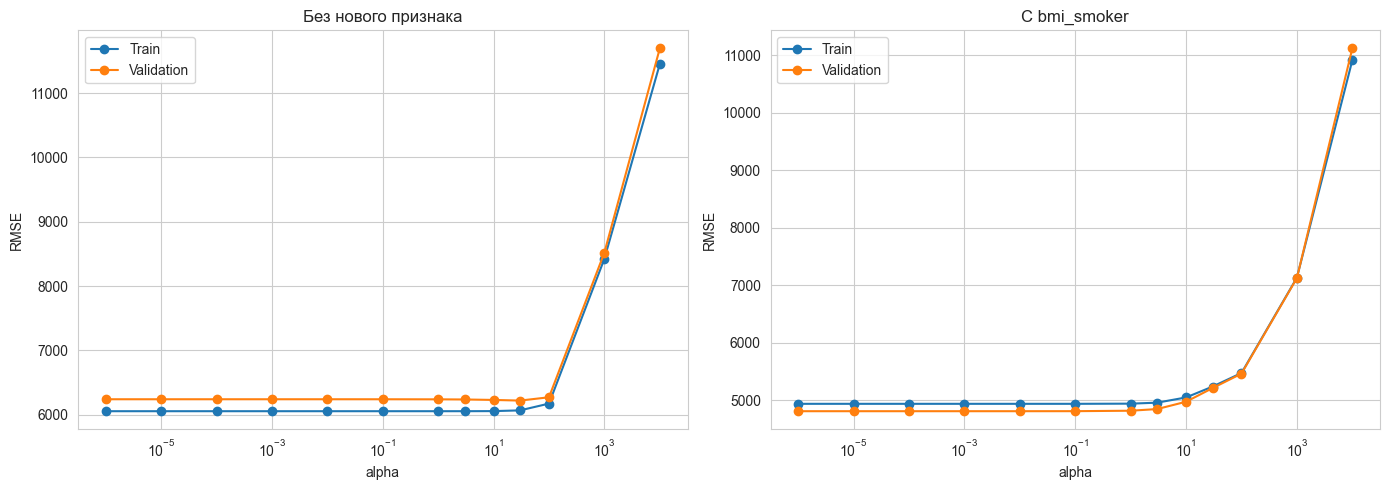

Лучший набор признаков: С bmi_smoker
Лучшая alpha: 1e-06
Ridge train
MAE: 2958.38424155374
RMSE: 4940.653867741467
R2: 0.834061631090943

Ridge validation
MAE: 3046.0795169964704
RMSE: 4812.166656259809
R2: 0.8494331715021302



In [22]:
from sklearn.linear_model import Ridge

alphas = [
    0.000001, 0.00001, 0.0001,
    0.001, 0.01, 0.1, 1, 3, 10, 30,
    100, 1000, 10000
]

feature_sets = {
    'Без нового признака': [
        col for col in X_train_scaled.columns
        if col != 'bmi_smoker'
    ],
    'С bmi_smoker': X_train_scaled.columns.tolist()
}

results = []

for variant, columns in feature_sets.items():
    for alpha in alphas:
        ridge = Ridge(alpha=alpha)

        ridge.fit(X_train_scaled[columns], y_train)

        train_pred = ridge.predict(X_train_scaled[columns])
        val_pred = ridge.predict(X_val_scaled[columns])

        results.append({
            'variant': variant,
            'alpha': alpha,
            'train_RMSE': np.sqrt(
                mean_squared_error(y_train, train_pred)
            ),
            'val_RMSE': np.sqrt(
                mean_squared_error(y_val, val_pred)
            ),
            'val_MAE': mean_absolute_error(y_val, val_pred),
            'val_R2': r2_score(y_val, val_pred)
        })

ridge_results = pd.DataFrame(results)

best_rows = ridge_results.loc[
    ridge_results.groupby('variant')['val_RMSE'].idxmin()
].copy()

display(best_rows.style.format({
    'alpha': '{:.6g}',
    'train_RMSE': '{:.2f}',
    'val_RMSE': '{:.2f}',
    'val_MAE': '{:.2f}',
    'val_R2': '{:.4f}'
}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, variant in zip(axes, feature_sets):
    subset = ridge_results[ridge_results['variant'] == variant]

    ax.plot(subset['alpha'], subset['train_RMSE'],
            marker='o', label='Train')
    ax.plot(subset['alpha'], subset['val_RMSE'],
            marker='o', label='Validation')

    ax.set_xscale('log')
    ax.set_xlabel('alpha')
    ax.set_ylabel('RMSE')
    ax.set_title(variant)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

best_row = ridge_results.loc[ridge_results['val_RMSE'].idxmin()]

best_alpha = float(best_row['alpha'])
best_variant = best_row['variant']
best_columns = feature_sets[best_variant]

print('Лучший набор признаков:', best_variant)
print('Лучшая alpha:', best_alpha)

ridge_model = Ridge(alpha=best_alpha)
ridge_model.fit(X_train_scaled[best_columns], y_train)

y_train_pred_ridge = ridge_model.predict(X_train_scaled[best_columns])
y_val_pred_ridge = ridge_model.predict(X_val_scaled[best_columns])

ridge_train_metrics = print_metrics(
    y_train, y_train_pred_ridge, 'Ridge train'
)
ridge_val_metrics = print_metrics(
    y_val, y_val_pred_ridge, 'Ridge validation'
)

Для модели Ridge выполнен подбор alpha по минимальному RMSE
на validation. Без нового признака лучшим среди проверенных
оказалось alpha = 30, с признаком bmi_smoker alpha = 0.000001.

Добавление bmi_smoker с подбором alpha улучшило качество:
RMSE на validation снизился с 6217.60 до 4812.17 (на 22.6%),
MAE с 4518.58 до 3046.08, а R² вырос с 0.7486 до 0.8494.
Это подтверждает пользу учёта взаимодействия BMI и курения
на данной validation-выборке.

У выбранной модели RMSE на train составляет 4940.65,
а на validation 4812.17. Ошибки близки, поэтому выраженных
признаков переобучения не наблюдается.

При больших alpha ошибки на обеих выборках растут,
слишком сильная регуляризация приводит к недообучению.
При малых alpha качество практически не меняется.
Выбранное значение соответствует очень слабой регуляризации,
поэтому модель близка к линейной регрессии без регуляризации.

По сравнению с baseline RMSE на validation снизился
с 12401.86 до 4812.17(примерно на 61.2%).
Для дальнейшего сравнения с моей реализацией выбираем
Ridge с признаком bmi_smoker и alpha = 0.000001.

In [23]:
def ridge_gradient(X, y, weights, bias, alpha):
    n = len(y)
    error = X @ weights + bias - y

    dw = (2 / n) * (X.T @ error + alpha * weights)
    db = 2 * np.mean(error)

    return dw, db


def calculate_rmse(X, y, weights, bias):
    error = X @ weights + bias - y
    return np.sqrt(np.mean(error ** 2))

Здесь заданы две функции: первая рассчитывает градиенты для обновления весов и свободного члена с учётом регуляризации Ridge, а вторая считает RMSE, чтобы оценивать ошибку модели.

In [39]:
def fit_my_ridge(model, X, y, X_val, y_val):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    X_val = np.asarray(X_val, dtype=float)
    y_val = np.asarray(y_val, dtype=float)

    model.weights = np.zeros(X.shape[1])
    model.bias = 0.0
    model.train_rmse_history = []
    model.val_rmse_history = []
    model.converged_ = False
    model.n_iter_ = 0

    for iteration in range(model.n_iterations + 1):
        dw, db = ridge_gradient(
            X, y, model.weights, model.bias, model.alpha
        )
        model.gradient_norm_ = np.sqrt(np.sum(dw ** 2) + db ** 2)

        if not np.isfinite(model.gradient_norm_):
            raise ValueError("Обучение расходится: уменьши learning_rate.")

        if model.gradient_norm_ < model.tol:
            model.converged_ = True
            break

        if iteration == model.n_iterations:
            break

        model.weights -= model.learning_rate * dw
        model.bias -= model.learning_rate * db

        train_rmse = calculate_rmse(X, y, model.weights, model.bias)
        val_rmse = calculate_rmse(X_val, y_val, model.weights, model.bias)

        if not np.isfinite(train_rmse) or not np.isfinite(val_rmse):
            raise ValueError("Обучение расходится: уменьши learning_rate.")

        model.train_rmse_history.append(train_rmse)
        model.val_rmse_history.append(val_rmse)
        model.n_iter_ = iteration + 1

    return model

Здесь задаётся функция обучения: на каждом шаге веса обновляются с помощью рассчитанных градиентов, а ошибки на обучении и валидации сохраняются для дальнейшего сравнения. Обучение заканчивается, когда градиент становится достаточно маленьким или достигнут лимит итераций.

In [25]:
class MyRidge:
    def __init__(
        self,
        alpha=1.0,
        learning_rate=0.05,
        n_iterations=100000,
        tol=1e-6
    ):
        self.alpha = alpha
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.tol = tol

    def fit(self, X, y, X_val, y_val):
        return fit_my_ridge(self, X, y, X_val, y_val)

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.weights + self.bias

Задаём класс моей модели, где хранятся гиперпараметры и методы обучения и предсказания.

In [30]:
learning_rates = [0.02, 0.05, 0.1, 0.2, 0.3, 0.4]

X_fit = np.asarray(X_train_scaled[best_columns], dtype=float)
X_valid = np.asarray(X_val_scaled[best_columns], dtype=float)
y_fit = np.asarray(y_train, dtype=float)
y_valid = np.asarray(y_val, dtype=float)

for name, values in [
    ('X_train', X_fit),
    ('X_val', X_valid),
    ('y_train', y_fit),
    ('y_val', y_valid)
]:
    if not np.isfinite(values).all():
        raise ValueError(f'В {name} есть NaN или бесконечные значения.')

my_models = {}
training_results = []

for lr in learning_rates:
    candidate = MyRidge(
        alpha=best_alpha,
        learning_rate=lr,
        n_iterations=100000,
        tol=1e-6
    )

    try:
        with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
            candidate.fit(X_fit, y_fit, X_valid, y_valid)

    except ValueError as error:
        if 'Обучение расходится' not in str(error):
            raise

        training_results.append({
            'learning_rate': lr,
            'iterations': candidate.n_iter_,
            'status': 'Расходимость',
            'gradient_norm': np.nan,
            'train_RMSE': np.nan,
            'val_RMSE': np.nan
        })
        continue

    my_models[lr] = candidate

    training_results.append({
        'learning_rate': lr,
        'iterations': candidate.n_iter_,
        'status': (
            'Сошлась' if candidate.converged_
            else 'Достигнут лимит итераций'
        ),
        'gradient_norm': candidate.gradient_norm_,
        'train_RMSE': candidate.train_rmse_history[-1],
        'val_RMSE': candidate.val_rmse_history[-1]
    })

training_results = pd.DataFrame(training_results)
display(training_results)

,learning_rate,iterations,status,gradient_norm,train_RMSE,val_RMSE
0,0.02,28501,Сошлась,9.996030e-07,4940.653868,4812.166656
1,0.05,11395,Сошлась,9.983461e-07,4940.653868,4812.166656
2,0.10,5692,Сошлась,9.998114e-07,4940.653868,4812.166656
3,0.20,2841,Сошлась,9.991373e-07,4940.653868,4812.166656
4,0.30,1891,Сошлась,9.948442e-07,4940.653868,4812.166656
5,0.40,1416,Сошлась,9.905102e-07,4940.653868,4812.166656


Проверены значения learning_rate от 0.02 до 0.4. Во всех случаях достигнута сходимость. Итоговые ошибки одинаковы до отображаемой части после запятой: RMSE на train 4940.65, на validation 4812.17. В проверенном диапазоне увеличение шага уменьшило число итераций до сходимости. Выбран learning_rate = 0.4, при котором потребовалось 1416 итераций.

Выбранный learning_rate: 0.4
Количество итераций: 1416


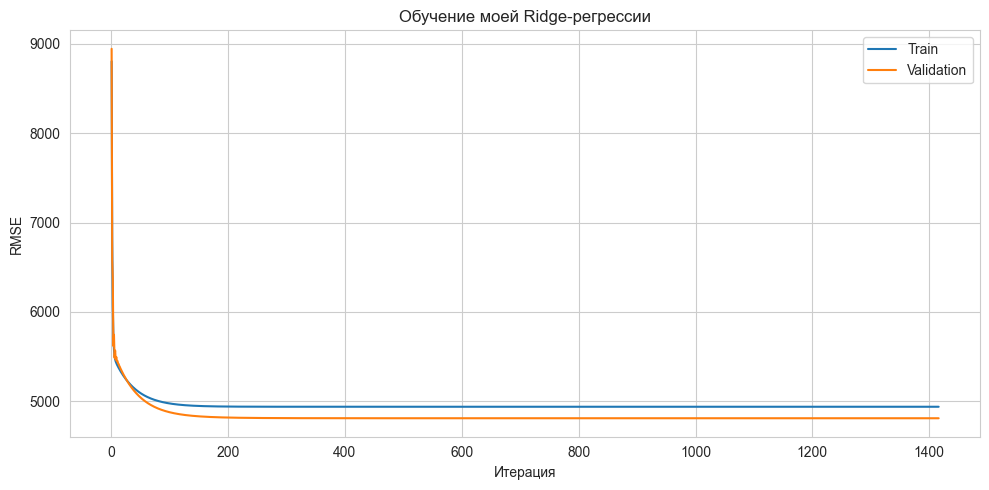

In [34]:
converged_results = training_results[
    training_results['status'] == 'Сошлась'
]

best_lr = float(
    converged_results.sort_values('iterations').iloc[0]['learning_rate']
)
my_model = my_models[best_lr]

print('Выбранный learning_rate:', best_lr)
print('Количество итераций:', my_model.n_iter_)

iterations = np.arange(1, my_model.n_iter_ + 1)

plt.figure(figsize=(10, 5))
plt.plot(iterations, my_model.train_rmse_history, label='Train')
plt.plot(iterations, my_model.val_rmse_history, label='Validation')
plt.xlabel('Итерация')
plt.ylabel('RMSE')
plt.title('Обучение моей Ridge-регрессии')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
y_train_pred_my = my_model.predict(X_train_scaled[best_columns])
y_val_pred_my = my_model.predict(X_val_scaled[best_columns])

my_train_metrics = print_metrics(
    y_train, y_train_pred_my, 'MyRidge train'
)
my_val_metrics = print_metrics(
    y_val, y_val_pred_my, 'MyRidge validation'
)

comparison_val = pd.DataFrame(
    [baseline_val_metrics, ridge_val_metrics, my_val_metrics],
    index=['Baseline', 'Sklearn Ridge', 'MyRidge']
)
display(comparison_val)

sklearn_val_pred = ridge_model.predict(X_val_scaled[best_columns])

print(
    'Максимальная разница коэффициентов:',
    np.max(np.abs(my_model.weights - ridge_model.coef_))
)
print(
    'Разница свободных коэффициентов:',
    abs(my_model.bias - ridge_model.intercept_)
)
print(
    'Максимальная разница предсказаний на validation:',
    np.max(np.abs(y_val_pred_my - sklearn_val_pred))
)
print(
    'Предсказания совпадают с абсолютной точностью 0.001:',
    np.allclose(y_val_pred_my, sklearn_val_pred, atol=0.001, rtol=0)
)

MyRidge train
MAE: 2958.3842415004233
RMSE: 4940.653867741467
R2: 0.834061631090943

MyRidge validation
MAE: 3046.0795171273994
RMSE: 4812.166656391157
R2: 0.8494331714939106



,MAE,RMSE,R2
Baseline,9333.597674,12401.862919,-0.000050
Sklearn Ridge,3046.079517,4812.166656,0.849433
MyRidge,3046.079517,4812.166656,0.849433


Максимальная разница коэффициентов: 1.9665578292915598e-05
Разница свободных коэффициентов: 1.8189894035458565e-12
Максимальная разница предсказаний на validation: 1.9062019418925047e-05
Предсказания совпадают с абсолютной точностью 0.001: True


При learning_rate = 0.4 моя модель достигла сходимости
за 1416 итераций. Ошибки train и validation быстро снижаются
в начале обучения, затем стабилизируются. Хотя примерно после
200 итераций кривые визуально почти горизонтальны, обучение
продолжается до выполнения критерия сходимости: нормы градиента
менее 0.000001. Ранняя остановка по validation не использовалась.

Итоговый RMSE составляет 4940.65 на train и 4812.17 на validation.
Ошибки близки, выраженных признаков переобучения не наблюдается.

После сходимости моя реализация практически совпадает
со sklearn Ridge. Максимальная разница коэффициентов составляет
около 0.00002, а предсказаний на validation около 0.000019.
Проверка совпадения предсказаний с точностью 0.001 пройдена.

Совпадение произошло, так как обе реализации используют одинаковые данные,
масштабирование, признаки и alpha и минимизируют эквивалентные
функции потерь.


In [36]:
y_test_baseline = np.full(len(y_test), baseline_value)

y_test_pred_ridge = ridge_model.predict(
    X_test_scaled[best_columns]
)
y_test_pred_my = my_model.predict(
    X_test_scaled[best_columns]
)

baseline_test_metrics = print_metrics(
    y_test, y_test_baseline, 'Baseline test'
)
ridge_test_metrics = print_metrics(
    y_test, y_test_pred_ridge, 'Sklearn Ridge test'
)
my_test_metrics = print_metrics(
    y_test, y_test_pred_my, 'MyRidge test'
)

comparison_test = pd.DataFrame(
    [baseline_test_metrics, ridge_test_metrics, my_test_metrics],
    index=['Baseline', 'Sklearn Ridge', 'MyRidge']
)

display(comparison_test.round(4))

improvement = (
    1 - ridge_test_metrics['RMSE'] / baseline_test_metrics['RMSE']
) * 100

print(f'Снижение RMSE относительно baseline: {improvement:.2f}%')

Baseline test
MAE: 8863.543384293194
RMSE: 11733.580921708091
R2: -0.00048641701914697855

Sklearn Ridge test
MAE: 2916.4846047005235
RMSE: 4662.18814890578
R2: 0.8420463582533444

MyRidge test
MAE: 2916.4846046788875
RMSE: 4662.188148390723
R2: 0.8420463582882444



,MAE,RMSE,R2
Baseline,8863.5434,11733.5809,-0.0005
Sklearn Ridge,2916.4846,4662.1881,0.8420
MyRidge,2916.4846,4662.1881,0.8420


Снижение RMSE относительно baseline: 60.27%


### Итоговый вывод

В ходе подготовки данных удален один дубликат.
Проверены все 139 потенциальных выбросов стоимости. Достаточных
оснований считать эти записи ошибочными не обнаружено,
поэтому они сохранены.

Анализ графиков и корреляций показал выраженную связь стоимости
с курением, а также различие зависимости стоимости от BMI
у курящих и некурящих. На этой основе добавлен признак взаимодействия этих двух признаков bmi_smoker, который помогает модели учитывать различие зависимости, описанное в предыдущем предложении.
После подбора alpha для обоих наборов признаков его добавление
снизило RMSE на validation с 6217.60 до 4812.17(на 22.6%).

Выбрана Ridge-регрессия с alpha = 0.000001. Для собственной
реализации проверены learning_rate от 0.02 до 0.4.
При learning_rate = 0.4 сходимость достигнута за 1416 итераций.
После сходимости коэффициенты и предсказания практически
совпадают со sklearn, поскольку реализации решают одну
и ту же задачу с одинаковыми данными и регуляризацией.

На тестовой выборке обе модели получили MAE = 2916.48,
RMSE = 4662.19 и R² = 0.8420. По сравнению с baseline,
предсказывающим среднее обучающей выборки, RMSE снизился
с 11733.58 до 4662.19, то есть на 60.27%.

Качество на train, validation и test сопоставимо:
R² составляет примерно 0.8341, 0.8494 и 0.8420 соответственно.
Выраженных признаков переобучения на данном разбиении
не наблюдается. Подбор параметров проводился по validation,
а test использовался для итоговой оценки.